In [78]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

URL = "https://archive.ics.uci.edu/static/public/" "222/bank+marketing.zip"
outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read("bank-additional.zip")))
df = pd.read_csv(inner.open("bank-additional/bank-additional.csv"), sep=";")
print(df.shape)

(4119, 21)


In [79]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [80]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
4114,30,admin.,married,basic.6y,no,yes,yes,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.958,5228.1,no
4115,39,admin.,married,high.school,no,yes,no,telephone,jul,fri,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.959,5228.1,no
4116,27,student,single,high.school,no,no,no,cellular,may,mon,...,2,999,1,failure,-1.8,92.893,-46.2,1.354,5099.1,no
4117,58,admin.,married,high.school,no,no,no,cellular,aug,fri,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
4118,34,management,single,high.school,no,yes,no,cellular,nov,wed,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no


In [81]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [82]:
print(df["y"].value_counts())

y
no     3668
yes     451
Name: count, dtype: int64


In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   str    
 2   marital         4119 non-null   str    
 3   education       4119 non-null   str    
 4   default         4119 non-null   str    
 5   housing         4119 non-null   str    
 6   loan            4119 non-null   str    
 7   contact         4119 non-null   str    
 8   month           4119 non-null   str    
 9   day_of_week     4119 non-null   str    
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   str    
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   float64
 18 

In [86]:
unknown_counts = (df == "unknown").sum()
unknown_counts[unknown_counts > 0].sort_values(ascending=False)

default      803
education    167
housing      105
loan         105
job           39
marital       11
dtype: int64

In [87]:
unknown_percent = (df == "unknown").mean() * 100
unknown_percent[unknown_percent > 0].sort_values(ascending=False)

default      19.495023
education     4.054382
housing       2.549162
loan          2.549162
job           0.946832
marital       0.267055
dtype: float64

In [88]:
df = df.drop(columns=["duration"])

In [89]:
df.shape

(4119, 20)

In [90]:
df.describe()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,40.113620,2.537266,960.422190,0.190337,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,10.313362,2.568159,191.922786,0.541788,1.563114,0.579349,4.594578,1.733591,73.667904
min,18.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,88.000000,35.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [91]:
df["y"].value_counts()

y
no     3668
yes     451
Name: count, dtype: int64

In [92]:
df["y"] = df["y"].map({"no": 0, "yes": 1})

In [93]:
nums = df.select_dtypes(include="number").columns

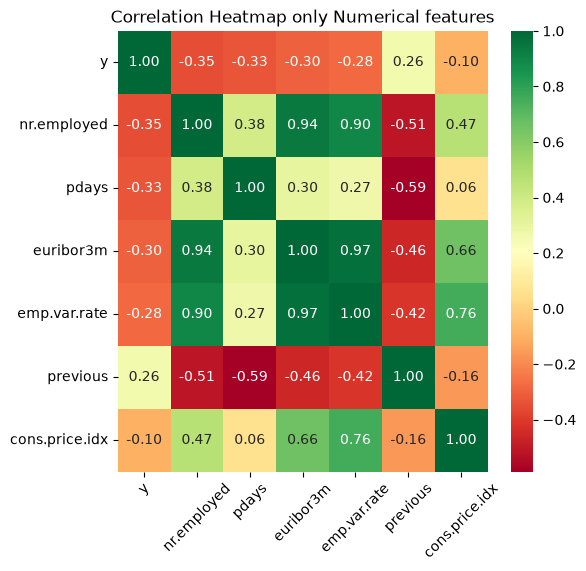

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_col_top = df[nums].corr()["y"].abs().sort_values(ascending=False).head(7).index

top_corr_matrix = df[corr_col_top].corr()

plt.figure(figsize=(6, 6))
sns.heatmap(data=top_corr_matrix, fmt=".2f", annot=True, cmap="RdYlGn")
plt.title("Correlation Heatmap only Numerical features")
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

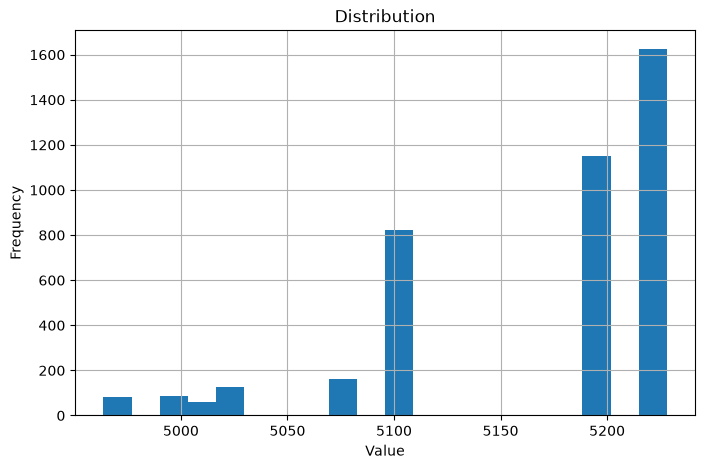

In [95]:
df["nr.employed"].hist(figsize=(8, 5), bins=20)
plt.title("Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

In [96]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
       'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["y"])
y = df["y"]

X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, stratify=y
)

In [116]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)


def metrics(X_test, y_test, model):
    y_pred = model.predict(X_test)
    y_probs = model.predict_proba(X_test)[:, 1]

    result = {
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Precision": round(precision_score(y_test, y_pred), 2),
        "Recall": round(recall_score(y_test, y_pred), 2),
        "F1 Score": round(f1_score(y_test, y_pred), 2),
        "ROC AUC": round(roc_auc_score(y_test, y_probs), 2),
    }

    return pd.DataFrame(result, index=[0])

In [124]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    criterion="gini",
    random_state=42,
)

dt.fit(X_train, y_train)

metrics(X_test, y_test, dt)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.87,0.35,0.21,0.26,0.57


In [ ]:
from sklearn.ensemble import RandomForestClassifier

X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    criterion="gini",
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train, y_train)

train_preds = rf.predict(X_train)
test_preds = rf.predict(X_test)

rf_metrics = metrics(X_test, y_test, rf)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.89,0.5,0.16,0.24,0.74


In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

bagging.fit(X_train, y_train)

metrics(X_test, y_test, bagging)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.89,0.46,0.19,0.27,0.73


In [120]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42,
)

ada.fit(X_train, y_train)

metrics(X_test, y_test, ada)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,0.9,0.57,0.18,0.27,0.76


In [125]:
df_ada = metrics(X_test, y_test, ada)
df_rf = metrics(X_test, y_test, rf)
df_bagging = metrics(X_test, y_test, bagging)
df_dt = metrics(X_test, y_test, dt)

final_report = pd.concat([df_ada, df_rf, df_bagging, df_dt])
final_report.index = [
    "Ada Boost Classifier",
    "Random Forest",
    "Bagging",
    "Decision Tree",
]

final_report

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Ada Boost Classifier,0.90,0.57,0.18,0.27,0.76
Random Forest,0.89,0.50,0.16,0.24,0.74
Bagging,0.89,0.46,0.19,0.27,0.73
Decision Tree,0.87,0.35,0.21,0.26,0.57
